In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the cleaned data set

df = pd.read_csv(
    "data/charging_records_cleaned.csv"
)

print("Cleaned dataset loaded successfully!")

print("Dataset shape:", df.shape)

display(df.head())

Cleaned dataset loaded successfully!
Dataset shape: (72826, 14)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalculatedDuration
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,185.0
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,90.0
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,60.0
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,00:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,344.0
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,00:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,300.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72826 entries, 0 to 72825
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   UserID              72826 non-null  int64  
 1   ChargerID           72826 non-null  int64  
 2   ChargerCompany      72826 non-null  int64  
 3   Location            72826 non-null  object 
 4   ChargerType         72826 non-null  int64  
 5   StartDay            72826 non-null  object 
 6   StartTime           72826 non-null  object 
 7   EndDay              72826 non-null  object 
 8   EndTime             72826 non-null  object 
 9   StartDatetime       72826 non-null  object 
 10  EndDatetime         72826 non-null  object 
 11  Duration            72826 non-null  int64  
 12  Demand              72826 non-null  float64
 13  CalculatedDuration  72826 non-null  float64
dtypes: float64(2), int64(5), object(7)
memory usage: 7.8+ MB


In [6]:
# Convert datetime columns - When you save a DataFrame as CSV, its datetime columns are stored as text. 
# Therefore, you need to convert them back to datetime after loading the file.

df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"],
    errors="coerce"
)

df["EndDatetime"] = pd.to_datetime(
    df["EndDatetime"],
    errors="coerce"
)

print(df[[
    "StartDatetime",
    "EndDatetime"
]].dtypes)


df["StartDay"] = pd.to_datetime(
    df["StartDay"], errors="coerce"
)

df["EndDay"] = pd.to_datetime(
    df["EndDay"], errors="coerce"
)


df["StartTime"] = pd.to_datetime(
    df["StartTime"],
    format="%H:%M:%S",
    errors="coerce"
).dt.time

df["EndTime"] = pd.to_datetime(
    df["EndTime"],
    format="%H:%M:%S",
    errors="coerce"
).dt.time

StartDatetime    datetime64[ns]
EndDatetime      datetime64[ns]
dtype: object


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72826 entries, 0 to 72825
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   UserID              72826 non-null  int64         
 1   ChargerID           72826 non-null  int64         
 2   ChargerCompany      72826 non-null  int64         
 3   Location            72826 non-null  object        
 4   ChargerType         72826 non-null  int64         
 5   StartDay            72826 non-null  datetime64[ns]
 6   StartTime           72826 non-null  object        
 7   EndDay              72826 non-null  datetime64[ns]
 8   EndTime             72826 non-null  object        
 9   StartDatetime       72826 non-null  datetime64[ns]
 10  EndDatetime         72826 non-null  datetime64[ns]
 11  Duration            72826 non-null  int64         
 12  Demand              72826 non-null  float64       
 13  CalculatedDuration  72826 non-null  float64   

In [8]:
# Create time-based features - use the start timestamp to extract the hour, weekday, month, and weekend status.

df["Hour"] = df["StartDatetime"].dt.hour

df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek

df["Month"] = df["StartDatetime"].dt.month

df["IsWeekend"] = (
    df["DayOfWeek"] >= 5
).astype(int)

df["DayName"] = df["StartDatetime"].dt.day_name()

df["TimeOfDay"] = pd.cut(
    df["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

display(df.head())

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalculatedDuration,Hour,DayOfWeek,Month,IsWeekend,DayName,TimeOfDay
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,185.0,20,3,9,0,Thursday,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,90.0,20,2,9,0,Wednesday,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,60.0,18,2,9,0,Wednesday,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,00:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,344.0,18,3,9,0,Thursday,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,00:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,300.0,19,6,9,1,Sunday,Evening


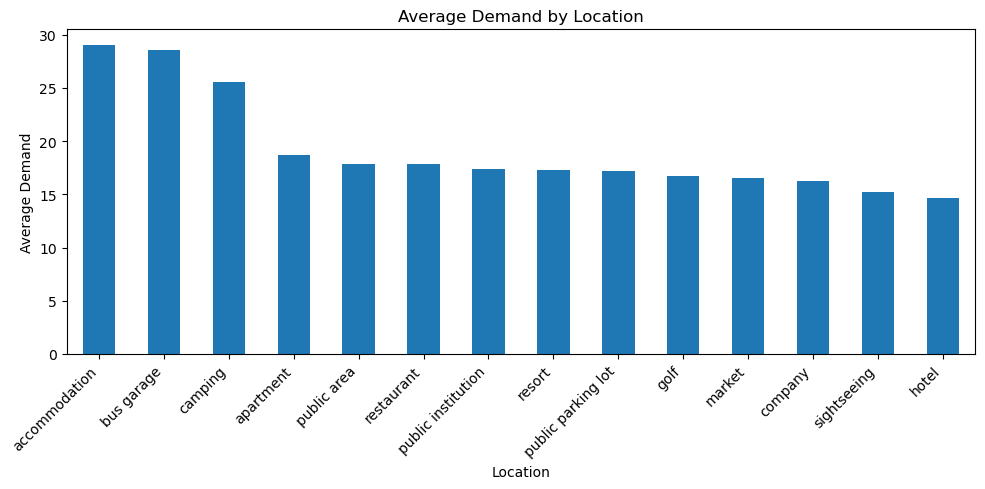

In [9]:
# Chart1 - Demand by location

(
    df.groupby("Location")["Demand"]
    .mean()
    .sort_values(ascending=False)
    .plot(kind="bar", figsize=(10, 5))
)
plt.title("Average Demand by Location")
plt.ylabel("Average Demand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

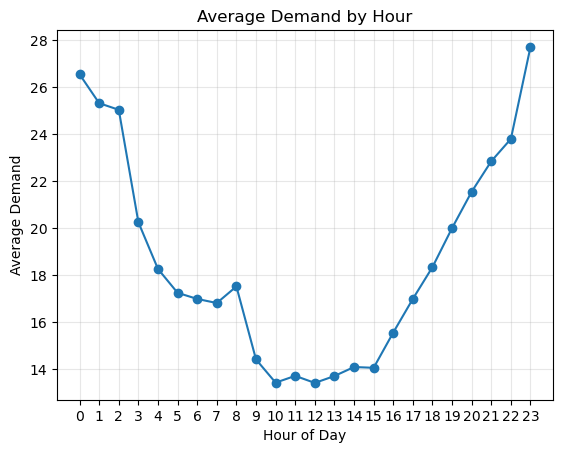

In [10]:
# Chart 2 — Demand by hour

(
    df.groupby("Hour")["Demand"]
    .mean()
    .plot(kind="line", marker="o")
)
plt.title("Average Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

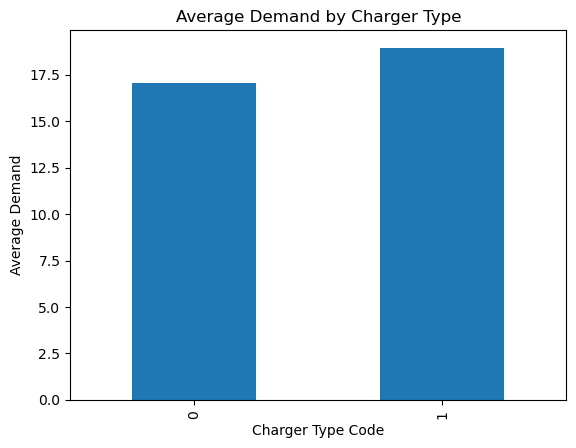

In [11]:
# Chart 3 — Demand by charger type

(
    df.groupby("ChargerType")["Demand"]
    .mean()
    .plot(kind="bar")
)
plt.title("Average Demand by Charger Type")
plt.xlabel("Charger Type Code")
plt.ylabel("Average Demand")
plt.show()

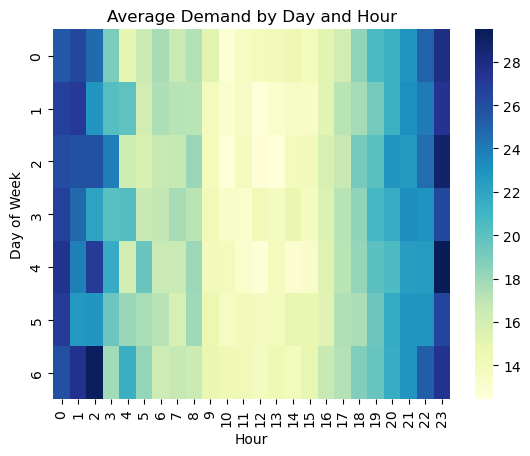

In [12]:
# Chart 4 — Weekday and hour patterns

heatmap_data = df.pivot_table(
    index="DayOfWeek",
    columns="Hour",
    values="Demand",
    aggfunc="mean"
)

sns.heatmap(heatmap_data, cmap="YlGnBu")
plt.title("Average Demand by Day and Hour")
plt.xlabel("Hour")
plt.ylabel("Day of Week")
plt.show()

In [13]:
# Analyse charging activity and utilization

location_summary = (
    df.groupby("Location")
    .agg(
        Sessions=("Demand", "size"),
        AverageDemand=("Demand", "mean"),
        TotalDemand=("Demand", "sum"),
        AverageDuration=("Duration", "mean")
    )
    .sort_values("Sessions", ascending=False)
)

display(location_summary)

,Sessions,AverageDemand,TotalDemand,AverageDuration
Location,,,,
public area,14076,17.899891,251958.87,133.155016
apartment,14036,18.744879,263103.12,204.891351
resort,8854,17.280838,153004.54,170.970070
hotel,8598,14.702966,126416.10,146.825076
company,7557,16.248039,122786.43,150.989678
public institution,7023,17.399318,122195.41,120.236366
public parking lot,3394,17.187510,58334.41,50.149087
market,2988,16.506272,49320.74,97.441432
restaurant,2222,17.813123,39580.76,156.572007
